# 流程图
- 采用langgraph构造动态节点
1. session_id 保持会话记录
2. state 保持状态，在同一个session中，state会被不断更新


In [35]:
from typing import Annotated, Literal, TypedDict

from langchain_core.language_models.chat_models import BaseChatModel
from langchain_core.messages import HumanMessage, SystemMessage, ToolMessage  # 消息类型
from langchain_core.tools import tool  # 导入tool装饰器
from langgraph.checkpoint.memory import InMemorySaver  # 保存状态到内存中（按 thread_id 分会话）
from langgraph.graph import END, START, StateGraph  # 构建状态图
from langgraph.graph.message import add_messages  # 追加新的信息
from langgraph.prebuilt import ToolNode  # 预构建的工具节点
from langgraph.types import Command, interrupt  # Command: 跨节点跳转; interrupt: 中断等待人工审核

from app.agents.providers import get_llm_provider


# 初始化模型厂商
def _build_model(model_name: str | None = None) -> BaseChatModel:
    """实现providers工厂函数中的具体模型构建商
    Args:
        model_name (str | None, optional): 模型名称. Defaults to None.
    Returns:
        BaseChatModel: 返回构建的模型实例
    """
    return get_llm_provider().build_model(model_name=model_name)


llm = _build_model("gpt-oss:120b")


# ============ 定义工具 ============
# 工具是 async def，所以整张图只能用 await graph.ainvoke(...) 驱动。
# 同步 graph.invoke(...) 不会抛错，但会静默失败：ToolNode 默认 handle_tool_errors=True，
# 会把 NotImplementedError("StructuredTool does not support sync invocation.")
# 包成 status="error" 的 ToolMessage 喂回模型，模型于是拿着一条错误信息继续作答。
# return_direct 是 AgentExecutor / prebuilt agent 的语义，自建图里 ToolNode 不认，故去掉。


@tool(description="RAG内部知识库搜索工具")
async def search_rag_tool(query: str) -> str:
    """RAG内部知识库搜索工具
    Args:
        query (str): 搜索查询字符串
    Returns:
        str: 搜索结果的相关信息
    """
    result = f"搜索结果: {query} 的相关信息"
    return result


@tool(description="外部网站爬虫工具")
async def web_scraper_tool(url: str) -> str:
    """外部网站爬虫工具
    Args:
        url (str): 需要爬取的网页URL
    Returns:
        str: 爬取结果的网页内容
    """
    result = f"爬取结果: {url} 的网页内容"
    return result


@tool(description="PostgreSQL数据分析工具")
async def postgresql_analysis_tool(query: str) -> str:
    """PostgreSQL数据分析工具
    Args:
        query (str): 需要分析的SQL查询语句
    Returns:
        str: 分析结果的相关信息
    """
    result = f"PostgreSQL分析结果: {query} 的数据分析结果"
    return result


tools = [search_rag_tool, web_scraper_tool, postgresql_analysis_tool]
llm_with_tools = llm.bind_tools(tools)  # 把工具 schema 交给模型，模型才会产出 tool_calls


# ============ 自定义 State ============
# messages 用 add_messages 做 reducer（追加而非覆盖），其余字段默认覆盖语义。
class AgentState(TypedDict):
    messages: Annotated[list, add_messages]  # 消息列表 (自动追加新消息)
    message: str  # 本轮用户输入 / 最终回答（收尾节点回填）
    processed: bool  # 是否完成预处理


# ============ 安全策略 ============
# 敏感操作按「模型实际要调的工具名」判定，而不是对用户文本做关键词匹配：
# 关键词匹配既会漏（换个说法就绕过），也会误伤（正常提问里恰好出现"知识库"三个字）。
INTERNAL_KB_OPEN = False  # 内部知识库尚未开放
SENSITIVE_TOOLS = {"search_rag_tool"}  # 未开放期间，命中这些工具需人工审批

SYSTEM_PROMPT = "你是情报分析助手。需要外部信息时调用相应工具，不要臆造事实；拿到工具结果后用中文给出结论。"


# ============ 路由 ============
# 路由函数没有 IO，sync / async 都接受；这里跟节点保持一致写成 async
async def route_after_react(state: AgentState) -> Literal["sensitive_action", "tools", "execute"]:
    """路由策略（读模型真实产出的 tool_calls，相当于 tools_condition + 敏感度判定）
    1) 没有 tool_calls              -> execute（模型已给出最终答案）
    2) 有 tool_calls 且命中敏感工具 -> sensitive_action（人工审批）
    3) 有 tool_calls 且不敏感       -> tools（直接执行）
    """
    last = state["messages"][-1]
    tool_calls = getattr(last, "tool_calls", None) or []

    if not tool_calls:
        return "execute"
    if not INTERNAL_KB_OPEN and any(tc["name"] in SENSITIVE_TOOLS for tc in tool_calls):
        return "sensitive_action"
    return "tools"


# ============ 状态节点 ============
# 节点统一写成 async def：整张图由 await ainvoke 驱动，节点若是 sync def，
# LangGraph 会把它丢进默认线程池（线程名 asyncio_N）跑 —— event loop 不会卡死，
# 但每个节点多一次线程切换，且模型调用会占住线程池 worker，搬进 FastAPI 后并发被线程数卡住。
async def greet_node(state: AgentState) -> dict:
    """欢迎节点：取出本轮用户输入，落到业务字段"""
    user_text = str(state["messages"][-1].content) if state["messages"] else ""
    print(f"[greet_node] 收到消息: {user_text}")
    return {"message": user_text, "processed": False}


async def process_node(state: AgentState) -> dict:
    """处理节点：预处理占位（真实场景放意图识别 / 输入清洗 / 权限校验）"""
    print(f"[process_node] 预处理: {state['message']}")
    return {"processed": True}


async def react_agent_node(state: AgentState) -> dict:
    """React Agent节点：由模型决定「直接回答」还是「调用工具」

    必须 await ainvoke —— 同步 invoke 走的是 httpx 同步连接池，
    在 async 节点里会把整个 event loop 阻塞到模型返回为止。
    """
    response = await llm_with_tools.ainvoke([SystemMessage(content=SYSTEM_PROMPT), *state["messages"]])
    return {"messages": [response]}


async def execute_node(state: AgentState) -> dict:
    """收尾节点：把最终回答回填到 state['message']，方便上层直接取用"""
    final_text = str(state["messages"][-1].content)
    print(f"[execute_node] 最终回答: {final_text}")
    return {"message": final_text}


async def sensitive_action_node(state: AgentState) -> Command[Literal["tools", "react_agent"]]:
    """执行敏感操作前请求人工审批

    返回 Command 而不是 dict：审批结果直接决定下一跳，比再挂一层条件边直观。
    Literal 注解让 draw_mermaid 能把这两条虚线分支画出来。
    interrupt() 不是协程（靠抛 GraphInterrupt 实现），在 async 节点里同样直接调用、不加 await。
    """
    tool_calls = state["messages"][-1].tool_calls

    # 暂停图的执行，等待人工决策；恢复：await graph.ainvoke(Command(resume="approve"), config)
    human_decision = interrupt(
        {
            "question": "是否批准执行以下操作？",
            "tool_calls": [{"name": tc["name"], "args": tc["args"]} for tc in tool_calls],
            "risk_level": "中等",
        }
    )

    if human_decision == "approve":
        # 不写任何消息：保持最后一条仍是带 tool_calls 的 AIMessage，ToolNode 才能接手
        return Command(goto="tools")

    # 拒绝：每个 tool_call 都要补一条 ToolMessage（否则消息链不合法），再回模型换个说法作答
    return Command(
        goto="react_agent",
        update={
            "messages": [
                ToolMessage(content="人工审批未通过，操作已取消。", name=tc["name"], tool_call_id=tc["id"])
                for tc in tool_calls
            ]
        },
    )

In [36]:
checkpointer = InMemorySaver()  # 生产环境换 AsyncPostgresSaver，state 才能跨进程存活

# StateGraph 的第二个位置参数是 context_schema（运行期只读上下文），不是"再合并一个 state"。
# 要让节点同时看到 messages 和业务字段，必须写在同一个 AgentState 里。
work = StateGraph(AgentState)

workflow = (
    work.add_node("greet", greet_node)
    .add_node("process", process_node)
    .add_node("sensitive_action", sensitive_action_node)
    .add_node("react_agent", react_agent_node)
    .add_node("tools", ToolNode(tools))
    .add_node("execute", execute_node)
    .add_edge(START, "greet")
    .add_edge("greet", "process")
    .add_edge("process", "react_agent")
    .add_conditional_edges(
        "react_agent",
        route_after_react,  # 自定义的路由函数 如果不需要敏感词工具 可以直接使用tools_condition 这个自带的路由函数
        {
            "tools": "tools",
            "sensitive_action": "sensitive_action",
            "execute": "execute",
        },
    )
    # 工具结果必须回到模型，否则模型永远看不到 ToolMessage —— 这才是 ReAct 的"再思考"闭环
    .add_edge("tools", "react_agent")
    # sensitive_action 不连边：它用 Command(goto=...) 自己决定去 tools 还是 react_agent
    .add_edge("execute", END)
)

graph = workflow.compile(checkpointer=checkpointer)

## 上方做法说明

### 1. 状态（State）
`AgentState` 是一个 `TypedDict`，字段分两类：

| 字段 | reducer | 作用 |
| --- | --- | --- |
| `messages` | `add_messages`（追加 + 按 id 去重覆盖） | 完整对话链：`Human → AI(tool_calls) → Tool → AI` |
| `message` | 默认（覆盖） | 本轮用户输入，收尾节点回填最终答案 |
| `processed` | 默认（覆盖） | 预处理是否完成 |

节点返回的是**增量 dict**，不是整个 state；LangGraph 按字段的 reducer 合并。所以只有 `messages` 会累积，其余字段是「后写覆盖」。

### 2. 会话与持久化
`compile(checkpointer=InMemorySaver())` + 调用时传 `config={"configurable": {"thread_id": ...}}`：
同一个 `thread_id` 就是同一个会话，state 在多次 `ainvoke` 之间自动续上；换一个 `thread_id` 就是全新会话。两个坑：
- `InMemorySaver` 只活在当前进程内，**重跑建图 cell 会新建实例、清空全部历史**，生产环境换 `AsyncPostgresSaver`
- 用错 `thread_id` 去 `resume` 不会报错，而是在新会话上从 `START` 重跑一遍，原会话永远停在中断点 —— 所以会话 id 用 `cfg()` 现场生成，别放全局变量

### 3. 节点职责
- `greet` —— 取出本轮用户输入写进 `message`
- `process` —— 预处理占位（意图识别 / 输入清洗 / 权限校验）
- `react_agent` —— 唯一调用模型的节点，用 `llm_with_tools` 让模型自己决定「直接回答」还是「产出 tool_calls」
- `tools` —— `ToolNode`，按 `tool_calls` 执行工具并写回 `ToolMessage`
- `sensitive_action` —— 敏感工具的人工审批闸门
- `execute` —— 收尾，把最终回答回填到 `message`

### 4. 路由：读 `tool_calls`，不做关键词匹配
`route_after_react` 判断的是**模型实际产出的 `tool_calls`**：

```
无 tool_calls                → execute   （模型已给出最终答案）
有 tool_calls + 命中敏感工具 → sensitive_action
有 tool_calls + 不敏感       → tools
```

等价于官方 `tools_condition`，只是多了一层敏感度分流。之前那版对用户文本做关键词匹配（`"知识库" in text`）不可靠：模型换个说法就绕过（漏判），用户随口提到"分析"又会误触（误判）。误触的后果还很隐蔽 —— `ToolNode` 拿不到 `tool_calls` 时**不报错**，只返回 `{"messages": []}`，白跑一个节点，问题被吞掉。

### 5. ReAct 闭环
`tools → react_agent` 这条回边是关键：工具结果必须回到模型，模型看过 `ToolMessage` 才能决定「继续调工具」还是「给出结论」。如果写成 `tools → execute`，工具结果永远不会被模型消费，那就只是一次固定的函数调用，不是 ReAct。循环上限由 `recursion_limit`（默认 25）兜底。

### 6. 人在回路（HITL）
`sensitive_action_node` 用 `interrupt(payload)` 把图**暂停**在这个节点：当前 state 已落盘到 checkpointer，`ainvoke` 立刻返回一个带 `__interrupt__` 的结果。人工决策后用 `Command(resume=...)` 恢复，节点会**从头重跑**，`interrupt()` 这次直接返回 resume 的值。

两条恢复路径用 `Command(goto=...)` 表达，所以这个节点不需要出边：
- `approve` → `Command(goto="tools")`，且**不写入任何消息** —— 保持最后一条仍是带 `tool_calls` 的 `AIMessage`，`ToolNode` 才认
- `reject` → 给每个 `tool_call` 补一条 `ToolMessage`（OpenAI/Ollama 的消息链要求 `tool_calls` 必须有对应回复，缺了下一次请求会 400），再回 `react_agent` 让模型换个说法作答

### 7. 异步：为什么整条链都用 async / await
三层里任意一层退回同步都会出问题：

| 层 | 写法 | 退回同步的后果 |
| --- | --- | --- |
| 驱动 | `await graph.ainvoke(...)` | 走 `ToolNode._func`（线程池），async 工具的 `.invoke()` 抛 `NotImplementedError`，又被默认的 `handle_tool_errors=True` 吞成 `status="error"` 的 `ToolMessage` —— **不报错，但模型拿到的是错误信息** |
| 节点 | `async def xxx_node` | sync 节点在异步运行下被丢进默认线程池（线程名 `asyncio_N`）：event loop 不会卡死，但每节点多一次线程切换，模型调用还会占住线程池 worker，搬进 FastAPI 后并发被线程数卡住 |
| 模型调用 | `await llm_with_tools.ainvoke(...)` | `invoke()` 走 httpx **同步**连接池（traceback 里会出现 `httpcore/_sync/`），在 async 节点里直接阻塞整个 event loop |

顺带一个收益：`ToolNode._afunc` 用 `asyncio.gather` 并发执行多个 `tool_calls`，而 `_func` 只是线程池 map —— 模型一次并行调多个工具时异步路径更快。

不需要 `await` 的两处：
- `route_after_react` —— 纯判断无 IO，sync / async LangGraph 都接受
- `interrupt()` —— 不是协程，靠抛 `GraphInterrupt` 实现，**不能** `await`

现在节点全是 async，同步 `graph.invoke()` 会直接抛 `TypeError: No synchronous function provided to "greet"` —— 显式失败，比静默失败好。

执行环境：notebook（ipykernel 自带 event loop）可以顶层 `await`；搬到普通 `.py` 必须 `asyncio.run(main())`，或放在 FastAPI 的 `async def` 路由里 await。

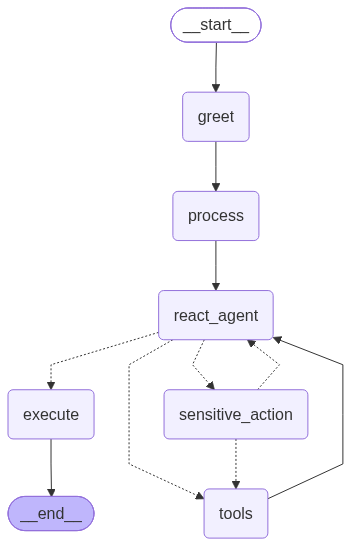

In [37]:
from IPython.display import Image

Image(graph.get_graph().draw_mermaid_png())

# print(graph.get_graph().draw_mermaid())

## 运行演示（离线模式，不接真模型）

下面用一个脚本化的假模型 `FakeChatModel` 顶替 `llm_with_tools`，只验证图的流转：条件路由、`ToolNode`、`interrupt` / `resume`、checkpointer 会话。**不需要 Ollama**。

- `react_agent_node` 只用到 `llm_with_tools.ainvoke()`，所以假模型只实现这一个方法即可，不必继承 `BaseChatModel`
- 工具是**真跑**的（异步执行、真写回 `ToolMessage`），只有"模型决定调哪个工具"这一步是脚本预设
- 每个场景开头都重新装一次假模型 —— 脚本会被上一个场景消耗掉
- 会话 id 一律用 `cfg("xxx")` 现场生成，别再用全局 `config` 变量：Jupyter 里所有 cell 共享命名空间，后执行的赋值会覆盖前面的（之前 `test_thread_001` 被 `demo-1` 顶掉就是这个原因）
- 想切回真模型：重新执行 `llm_with_tools = llm.bind_tools(tools)`

In [38]:
# ============ 离线测试脚手架（不连模型） ============
from langchain_core.messages import AIMessage


def cfg(thread_id: str) -> dict:
    """按会话 id 生成 RunnableConfig

    会话归属写在调用点，而不是全局 config 变量 ——
    Jupyter 所有 cell 共享命名空间，后执行的 `config = ...` 会覆盖前面的。
    """
    return {"configurable": {"thread_id": thread_id}}


class FakeChatModel:
    """脚本化假模型，用来顶替 llm_with_tools

    react_agent_node 只调用 .ainvoke()，所以不必继承 BaseChatModel。
    脚本耗尽后固定返回最后一条，ReAct 回路多转一圈也不会 IndexError。
    """

    def __init__(self, script: list[AIMessage]) -> None:
        self.script = list(script)
        self.calls = 0

    async def ainvoke(self, messages: list, *args, **kwargs) -> AIMessage:
        msg = self.script[min(self.calls, len(self.script) - 1)]
        self.calls += 1
        hint = [tc["name"] for tc in msg.tool_calls] if msg.tool_calls else repr(msg.content)
        print(f"[fake_llm] 第 {self.calls} 次调用（收到 {len(messages)} 条消息）-> {hint}")
        return msg


def ai_tool_call(name: str, args: dict, call_id: str = "call-1") -> AIMessage:
    """构造一条「模型要求调用工具」的 AIMessage"""
    return AIMessage(
        content="",
        tool_calls=[{"name": name, "args": args, "id": call_id, "type": "tool_call"}],
    )


print("离线脚手架就绪: cfg() / FakeChatModel / ai_tool_call")

离线脚手架就绪: cfg() / FakeChatModel / ai_tool_call


In [39]:
# ---- 场景 1：非敏感工具（爬虫），一路跑到底 ----
# 第 1 轮模型要求调工具 -> ToolNode 真跑 -> 结果回到模型 -> 第 2 轮给出结论
llm_with_tools = FakeChatModel(
    [
        ai_tool_call("web_scraper_tool", {"url": "https://example.com"}),
        AIMessage(content="example.com 的要点：这是一个用于示例的站点。"),
    ]
)

result = await graph.ainvoke(
    {"messages": [HumanMessage(content="爬取 https://example.com 并总结要点")]},
    cfg("demo-1"),
)

for m in result["messages"]:
    m.pretty_print()
print("最终答案:", result["message"], "| processed =", result["processed"])

[greet_node] 收到消息: 爬取 https://example.com 并总结要点
[process_node] 预处理: 爬取 https://example.com 并总结要点
[fake_llm] 第 1 次调用（收到 2 条消息）-> ['web_scraper_tool']
[fake_llm] 第 2 次调用（收到 4 条消息）-> 'example.com 的要点：这是一个用于示例的站点。'
[execute_node] 最终回答: example.com 的要点：这是一个用于示例的站点。
================================ Human Message =================================

爬取 https://example.com 并总结要点
================================== Ai Message ==================================
Tool Calls:
  web_scraper_tool (call-1)
 Call ID: call-1
  Args:
    url: https://example.com
================================= Tool Message =================================
Name: web_scraper_tool

爬取结果: https://example.com 的网页内容
================================== Ai Message ==================================

example.com 的要点：这是一个用于示例的站点。
最终答案: example.com 的要点：这是一个用于示例的站点。 | processed = True


In [40]:
# ---- 场景 2a：敏感工具（内部知识库）-> 停在人工审批 ----
llm_with_tools = FakeChatModel(
    [
        ai_tool_call("search_rag_tool", {"query": "A 项目"}),
        AIMessage(content="根据内部知识库：A 项目当前处于验证阶段。"),
    ]
)

paused = await graph.ainvoke(
    {"messages": [HumanMessage(content="查一下内部知识库里关于 A 项目的资料")]},
    cfg("demo-2"),
)

print("审批表单:", paused["__interrupt__"][0].value)
print("图当前停在:", graph.get_state(cfg("demo-2")).next)  # ('sensitive_action',)

[greet_node] 收到消息: 查一下内部知识库里关于 A 项目的资料
[process_node] 预处理: 查一下内部知识库里关于 A 项目的资料
[fake_llm] 第 1 次调用（收到 2 条消息）-> ['search_rag_tool']
审批表单: {'question': '是否批准执行以下操作？', 'tool_calls': [{'name': 'search_rag_tool', 'args': {'query': 'A 项目'}}], 'risk_level': '中等'}
图当前停在: ('sensitive_action',)


In [41]:
# ---- 场景 2b：批准 -> 恢复执行 ----
# resume 的值就是 interrupt() 的返回值。
# thread_id 必须还是 demo-2：换成别的 id 不会报错，而是在新会话上从 START 重跑一遍，
# 原来那个中断会话则永远停在 sensitive_action。
resumed = await graph.ainvoke(Command(resume="approve"), cfg("demo-2"))

for m in resumed["messages"]:
    m.pretty_print()
print("最终答案:", resumed["message"])

[fake_llm] 第 2 次调用（收到 4 条消息）-> '根据内部知识库：A 项目当前处于验证阶段。'
[execute_node] 最终回答: 根据内部知识库：A 项目当前处于验证阶段。
================================ Human Message =================================

查一下内部知识库里关于 A 项目的资料
================================== Ai Message ==================================
Tool Calls:
  search_rag_tool (call-1)
 Call ID: call-1
  Args:
    query: A 项目
================================= Tool Message =================================
Name: search_rag_tool

搜索结果: A 项目 的相关信息
================================== Ai Message ==================================

根据内部知识库：A 项目当前处于验证阶段。
最终答案: 根据内部知识库：A 项目当前处于验证阶段。


In [42]:
# ---- 场景 3：拒绝 -> 补 ToolMessage 后回到模型换个说法作答 ----
llm_with_tools = FakeChatModel(
    [
        ai_tool_call("search_rag_tool", {"query": "A 项目"}),
        AIMessage(content="内部知识库暂未开放，我无法查询，建议走线下审批流程。"),
    ]
)

await graph.ainvoke(
    {"messages": [HumanMessage(content="查一下内部知识库里关于 A 项目的资料")]},
    cfg("demo-3"),
)
rejected = await graph.ainvoke(Command(resume="reject"), cfg("demo-3"))

for m in rejected["messages"]:
    m.pretty_print()
print("最终答案:", rejected["message"])

[greet_node] 收到消息: 查一下内部知识库里关于 A 项目的资料
[process_node] 预处理: 查一下内部知识库里关于 A 项目的资料
[fake_llm] 第 1 次调用（收到 2 条消息）-> ['search_rag_tool']
[fake_llm] 第 2 次调用（收到 4 条消息）-> '内部知识库暂未开放，我无法查询，建议走线下审批流程。'
[execute_node] 最终回答: 内部知识库暂未开放，我无法查询，建议走线下审批流程。
================================ Human Message =================================

查一下内部知识库里关于 A 项目的资料
================================== Ai Message ==================================
Tool Calls:
  search_rag_tool (call-1)
 Call ID: call-1
  Args:
    query: A 项目
================================= Tool Message =================================
Name: search_rag_tool

人工审批未通过，操作已取消。
================================== Ai Message ==================================

内部知识库暂未开放，我无法查询，建议走线下审批流程。
最终答案: 内部知识库暂未开放，我无法查询，建议走线下审批流程。


In [43]:
# ---- 一键自检：4 条路径全跑一遍并断言（纯流程，不碰真模型）----
async def run_case(script: list[AIMessage], text: str, thread_id: str, resume: str | None = None) -> dict:
    """装上脚本假模型跑一轮；resume 不为 None 时再送一次人工决策"""
    global llm_with_tools
    llm_with_tools = FakeChatModel(script)
    out = await graph.ainvoke({"messages": [HumanMessage(content=text)]}, cfg(thread_id))
    if resume is not None:
        assert "__interrupt__" in out, "预期停在人工审批，实际直接跑完了"
        out = await graph.ainvoke(Command(resume=resume), cfg(thread_id))
    return out


# 1) 无 tool_calls -> 直接 execute
out = await run_case([AIMessage(content="直接回答")], "你好", "check-1")
assert [type(m).__name__ for m in out["messages"]] == ["HumanMessage", "AIMessage"]
assert out["message"] == "直接回答" and out["processed"] is True

# 2) 非敏感工具 -> tools -> 回到模型（ReAct 闭环）
out = await run_case(
    [ai_tool_call("postgresql_analysis_tool", {"query": "select 1"}), AIMessage(content="分析完成")],
    "分析一下数据库",
    "check-2",
)
assert [type(m).__name__ for m in out["messages"]] == ["HumanMessage", "AIMessage", "ToolMessage", "AIMessage"]
assert "PostgreSQL分析结果" in out["messages"][2].content
assert out["messages"][2].status == "success"  # async 工具真的被执行了，不是被吞掉的错误

# 3) 敏感工具 + 批准 -> 工具照常执行
out = await run_case(
    [ai_tool_call("search_rag_tool", {"query": "A"}), AIMessage(content="已给出结论")],
    "查内部知识库",
    "check-3",
    resume="approve",
)
assert "搜索结果" in out["messages"][2].content

# 4) 敏感工具 + 拒绝 -> 工具不执行，补一条拒绝的 ToolMessage
out = await run_case(
    [ai_tool_call("search_rag_tool", {"query": "A"}), AIMessage(content="无法查询")],
    "查内部知识库",
    "check-4",
    resume="reject",
)
assert out["messages"][2].content == "人工审批未通过，操作已取消。"

print("\n✅ 4 条路径全部通过：无工具直答 / 工具闭环 / 审批通过 / 审批拒绝")
print("切回真模型：llm_with_tools = llm.bind_tools(tools)")

[greet_node] 收到消息: 你好
[process_node] 预处理: 你好
[fake_llm] 第 1 次调用（收到 2 条消息）-> '直接回答'
[execute_node] 最终回答: 直接回答
[greet_node] 收到消息: 分析一下数据库
[process_node] 预处理: 分析一下数据库
[fake_llm] 第 1 次调用（收到 2 条消息）-> ['postgresql_analysis_tool']
[fake_llm] 第 2 次调用（收到 4 条消息）-> '分析完成'
[execute_node] 最终回答: 分析完成
[greet_node] 收到消息: 查内部知识库
[process_node] 预处理: 查内部知识库
[fake_llm] 第 1 次调用（收到 2 条消息）-> ['search_rag_tool']
[fake_llm] 第 2 次调用（收到 4 条消息）-> '已给出结论'
[execute_node] 最终回答: 已给出结论
[greet_node] 收到消息: 查内部知识库
[process_node] 预处理: 查内部知识库
[fake_llm] 第 1 次调用（收到 2 条消息）-> ['search_rag_tool']
[fake_llm] 第 2 次调用（收到 4 条消息）-> '无法查询'
[execute_node] 最终回答: 无法查询

✅ 4 条路径全部通过：无工具直答 / 工具闭环 / 审批通过 / 审批拒绝
切回真模型：llm_with_tools = llm.bind_tools(tools)
